# HDT 5: Árboles, Selección de Modelos y Bosques

**Ciencia de Datos, Sección A** · Asignada: martes 29 de septiembre · **Entrega: martes 6 de octubre, 23:59**

**Nombre:** Ana Sofía Eggenberger

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y split fijo): las verificaciones son exactas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Un gimnasio quiere saber qué socios van a darse de baja. Historial de 1,000 socios: `visitas` (al mes), `meses` (antigüedad como socio), `cuota` (quetzales al mes) y `se_va` (1 = no renovó). El mismo tipo de problema que la mora del banco de las sesiones 15 a 17, con otro negocio.

La celda genera los datos completa; no hay nada que llenar aquí.

In [2]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(5)
n = 1000
visitas = np.minimum(rng.poisson(8, n), 30)
meses = rng.integers(1, 49, n)
cuota = rng.normal(400, 90, n).clip(200, 700).round(0)

riesgo = (-2.4 + 1.6 * (visitas <= 5) + 1.1 * (meses <= 12)
          + 0.9 * (cuota >= 480) + 1.1 * ((visitas <= 5) & (meses <= 12)))
se_va = (rng.random(n) < 1 / (1 + np.exp(-riesgo))).astype(int)

df = pd.DataFrame({"visitas": visitas, "meses": meses, "cuota": cuota, "se_va": se_va})
columnas = ["visitas", "meses", "cuota"]
X_train, X_test, y_train, y_test = train_test_split(
    df[columnas], df["se_va"], test_size=0.3, random_state=42)

print("socios:", len(df), "| fracción que se va:", df["se_va"].mean().round(3))
print("entrenamiento:", len(X_train), "| examen:", len(X_test))
df.head()

socios: 1000 | fracción que se va: 0.187
entrenamiento: 700 | examen: 300


,visitas,meses,cuota,se_va
0,7,25,502.0,0
1,10,6,373.0,0
2,6,44,543.0,0
3,5,39,489.0,1
4,8,3,490.0,1


## Parte A · Un árbol (0.5 pt)

El modelo de preguntas de la sesión 15: elegir el corte que deja los grupos menos mezclados, y la profundidad como perilla.

### Ejercicio 1 (0.15): la mezcla a mano

Con la función `mezcla` de clase, sobre el **entrenamiento** (700 socios, 132 se van): (a) la mezcla sin cortar nada; (b) la mezcla promedio ponderada del corte `visitas <= 5`; (c) la del corte `meses <= 12`. ¿Cuál de los dos cortes gana, y coincide con la primera pregunta que elige un árbol de profundidad 1?

In [3]:
from sklearn.tree import DecisionTreeClassifier

def mezcla(se_van, se_quedan):
    p = se_van / (se_van + se_quedan)
    return 1 - p**2 - (1 - p)**2

def mezcla_del_corte(columna, corte):
    lado = X_train[columna] <= corte
    lado_izq = y_train[lado]
    lado_der = y_train[~lado]
    se_van_izq = int(lado_izq.sum())
    se_quedan_izq = len(lado_izq) - se_van_izq
    se_van_der = int(lado_der.sum())
    se_quedan_der = len(lado_der) - se_van_der
    mezcla_izq = mezcla(se_van_izq, se_quedan_izq)
    mezcla_der = mezcla(se_van_der, se_quedan_der)
    n_izq, n_der = len(lado_izq), len(lado_der)
    return (n_izq * mezcla_izq + n_der * mezcla_der) / (n_izq + n_der)

m_total = mezcla(int(y_train.sum()), int(len(y_train) - y_train.sum()))
m_visitas = mezcla_del_corte("visitas", 5)
m_meses = mezcla_del_corte("meses", 12)

print("mezcla total:", round(m_total, 3))
print("visitas <= 5:", round(m_visitas, 3))
print("meses <= 12:", round(m_meses, 3))
arbol_uno = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_train, y_train)
indice_pregunta = arbol_uno.tree_.feature[0]
print("primera pregunta del árbol:", columnas[indice_pregunta],
      "<=", round(arbol_uno.tree_.threshold[0], 1))
# Respuesta: gana visitas <= 5 porque deja una mezcla menor; coincide con el árbol.

assert round(m_total, 3) == 0.306
assert round(m_visitas, 3) == 0.252
assert round(m_meses, 3) == 0.290

mezcla total: 0.306
visitas <= 5: 0.252
meses <= 12: 0.29
primera pregunta del árbol: visitas <= 5.5


### Ejercicio 2 (0.20): la profundidad es la perilla

Para cada profundidad en [1, 2, 3, 4, 6, 8, 12]: entrenar un árbol (`random_state=0`) y guardar aciertos en entrenamiento y en examen. Graficar las dos curvas (AZUL entrenamiento, ROJO examen) con `eje_limpio`. Responder en un comentario: ¿qué profundidad elegirían y por qué?

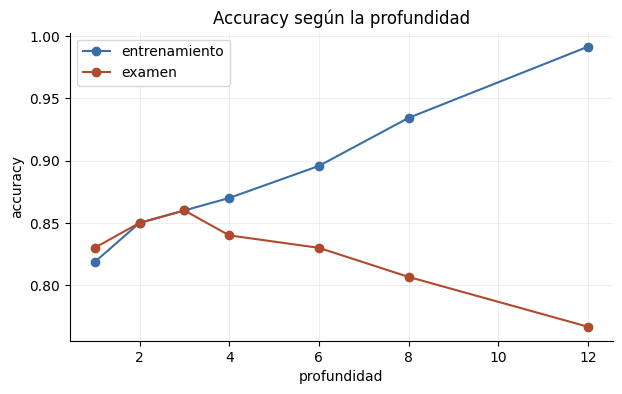

In [4]:
from sklearn.tree import DecisionTreeClassifier

profundidades = [1, 2, 3, 4, 6, 8, 12]
acc_train = []
acc_test = []

for profundidad in profundidades:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=0)
    arbol.fit(X_train, y_train)
    acc_train.append(arbol.score(X_train, y_train))
    acc_test.append(arbol.score(X_test, y_test))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(profundidades, acc_train, marker="o", color=AZUL, label="entrenamiento")
ax.plot(profundidades, acc_test, marker="o", color=ROJO, label="examen")
ax.set(xlabel="profundidad", ylabel="accuracy", title="Accuracy según la profundidad")
ax.legend()
eje_limpio(ax)
plt.show()

# Respuesta: elegiría profundidad 3: alcanza 0.86 en examen sin sobreajustar como el árbol de profundidad 12.

assert round(acc_test[2], 2) == 0.86      # profundidad 3
assert round(acc_train[6], 3) == 0.991 and round(acc_test[6], 3) == 0.767

### Ejercicio 3 (0.15): un árbol solo es inestable

Entrenar 25 árboles **sin límite de profundidad**, cada uno con 350 socios del entrenamiento elegidos al azar (`np.random.default_rng(s).choice(len(X_train), 350, replace=False)` con `s` de 0 a 24), y guardar sus aciertos en el examen. Reportar el mínimo y el máximo. De paso: imprimir la primera pregunta de los árboles con `s` de 0 a 3 (profundidad 2) y observar que esa sí es estable.

In [5]:
from sklearn.tree import export_text

aciertos = []
for s in range(25):
    indices = np.random.default_rng(s).choice(len(X_train), 350, replace=False)
    arbol = DecisionTreeClassifier(random_state=0)
    arbol.fit(X_train.iloc[indices], y_train.iloc[indices])
    aciertos.append(arbol.score(X_test, y_test))
    if s <= 3:
        print(f"semilla {s}:")
        print(export_text(arbol, feature_names=columnas, max_depth=2))

print("mínimo:", round(min(aciertos), 3), "| máximo:", round(max(aciertos), 3))

assert round(min(aciertos), 3) == 0.73
assert round(max(aciertos), 3) == 0.8

semilla 0:
|--- visitas <= 5.50
|   |--- cuota <= 461.50
|   |   |--- meses <= 13.00
|   |   |   |--- truncated branch of depth 4
|   |   |--- meses >  13.00
|   |   |   |--- truncated branch of depth 9
|   |--- cuota >  461.50
|   |   |--- cuota <= 513.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- cuota >  513.50
|   |   |   |--- truncated branch of depth 4
|--- visitas >  5.50
|   |--- meses <= 9.50
|   |   |--- visitas <= 6.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- visitas >  6.50
|   |   |   |--- truncated branch of depth 10
|   |--- meses >  9.50
|   |   |--- visitas <= 6.50
|   |   |   |--- class: 0
|   |   |--- visitas >  6.50
|   |   |   |--- truncated branch of depth 16

semilla 1:
|--- visitas <= 5.50
|   |--- meses <= 13.00
|   |   |--- cuota <= 447.00
|   |   |   |--- class: 1
|   |   |--- cuota >  447.00
|   |   |   |--- truncated branch of depth 2
|   |--- meses >  13.00
|   |   |--- visitas <= 4.50
|   |   |   |--- truncated branch of de

## Parte B · Elegir sin trampa (0.5 pt)

La sesión 16 en tres pasos: comparar candidatos con validación cruzada, afinar perillas con búsqueda, y tocar el examen una sola vez.

### Ejercicio 4 (0.20): tres candidatos, el mismo procedimiento

Comparar con validación cruzada estratificada de 5 pliegues (`StratifiedKFold(n_splits=5, shuffle=True, random_state=7)`) sobre el **entrenamiento**: logística (con escala, en Pipeline), árbol (`max_depth=4`) y kNN (con escala, `n_neighbors=15`). Imprimir promedio y desviación de cada uno. ¿Quién gana?

In [6]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
candidatos = {
    "logística": make_pipeline(StandardScaler(), LogisticRegression()),
    "árbol": DecisionTreeClassifier(max_depth=4, random_state=0),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}

promedios = {}
for nombre, candidato in candidatos.items():
    puntajes = cross_val_score(candidato, X_train, y_train, cv=cv)
    promedios[nombre] = puntajes.mean()
    print(nombre, "| promedio:", round(puntajes.mean(), 3),
          "| desviación:", round(puntajes.std(), 3))
# Respuesta: el árbol gana por tener el mayor promedio de validación cruzada.

assert round(promedios["árbol"], 3) == 0.846
assert promedios["árbol"] == max(promedios.values())

logística | promedio: 0.827 | desviación: 0.019
árbol | promedio: 0.846 | desviación: 0.012
kNN | promedio: 0.827 | desviación: 0.013


/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/anasofiaeggenberger/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_predi

### Ejercicio 5 (0.15): afinar las perillas del ganador

`GridSearchCV` sobre el árbol con `max_depth` en [2, 3, 4, 6] y `min_samples_leaf` en [5, 20, 50], usando el mismo `cv`. ¿Cuántas combinaciones probó? Imprimir la mejor y su puntaje.

In [7]:
from sklearn.model_selection import GridSearchCV

malla = {"max_depth": [2, 3, 4, 6],
         "min_samples_leaf": [5, 20, 50]}
busqueda = GridSearchCV(DecisionTreeClassifier(random_state=0),
                       param_grid=malla, cv=cv)
busqueda.fit(X_train, y_train)

print("mejores parámetros:", busqueda.best_params_)
print("mejor puntaje:", round(busqueda.best_score_, 3))
print("combinaciones evaluadas:", len(busqueda.cv_results_["params"]))

assert busqueda.best_params_ == {"max_depth": 3, "min_samples_leaf": 20}
assert round(busqueda.best_score_, 3) == 0.856

mejores parámetros: {'max_depth': 3, 'min_samples_leaf': 20}
mejor puntaje: 0.856
combinaciones evaluadas: 12


### Ejercicio 6 (0.15): el examen se usa una vez

Tomar `busqueda.best_estimator_` (ya viene entrenado con los 700) y evaluarlo en el examen. Responder en un comentario: ¿por qué este número puede ser distinto del 0.856 anterior, y por qué no se vale seguir probando modelos después de verlo?

In [8]:
examen_final = busqueda.best_estimator_.score(X_test, y_test)

# Respuesta: el examen puede diferir porque evalúa una muestra distinta; al verlo ya no es una evaluación imparcial para seguir eligiendo.

assert round(examen_final, 3) == 0.86

## Parte C · El bosque (0.8 pt)

La sesión 17: si un árbol baila, que voten muchos. Bootstrap, bagging a mano, OOB e importancias.

### Ejercicio 7 (0.20): bagging a mano

Para B en [1, 5, 25, 100]: entrenar B árboles sin límite, cada uno con una muestra bootstrap (`np.random.default_rng(b).integers(0, len(X_train), len(X_train))` con `b` de 0 a B-1), sumar sus votos sobre el examen y clasificar por mayoría (`votos / B >= 0.5`). Guardar los aciertos en `aciertos_bagging` y graficar contra B.

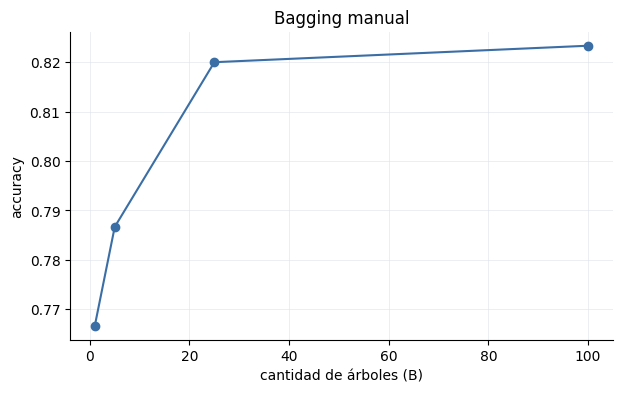

In [9]:
cantidades = [1, 5, 25, 100]
aciertos_bagging = []

for B in cantidades:
    votos = np.zeros(len(X_test), dtype=int)
    for b in range(B):
        indices = np.random.default_rng(b).integers(0, len(X_train), len(X_train))
        arbol = DecisionTreeClassifier(random_state=0)
        arbol.fit(X_train.iloc[indices], y_train.iloc[indices])
        votos += arbol.predict(X_test)
    predicciones = (votos / B >= 0.5).astype(int)
    aciertos_bagging.append(np.mean(predicciones == y_test.to_numpy()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cantidades, aciertos_bagging, marker="o", color=AZUL)
ax.set(xlabel="cantidad de árboles (B)", ylabel="accuracy",
       title="Bagging manual")
eje_limpio(ax)
plt.show()

assert [round(a, 3) for a in aciertos_bagging] == [0.767, 0.787, 0.82, 0.823]

### Ejercicio 8 (0.20): las perillas del bosque, medidas con OOB

Para `min_samples_leaf` en [1, 5, 10, 20, 50]: RandomForest de 300 árboles con `oob_score=True` (`random_state=0, n_jobs=-1`), guardar el OOB de cada uno en el diccionario `oobs`. Elegir el mejor y reportar su examen. Todo sin usar el examen para elegir: para eso está el OOB.

In [10]:
from sklearn.ensemble import RandomForestClassifier

oobs = {}
for msl in [1, 5, 10, 20, 50]:
    bosque = RandomForestClassifier(n_estimators=300,
                                   min_samples_leaf=msl,
                                   oob_score=True, random_state=0, n_jobs=-1)
    bosque.fit(X_train, y_train)
    oobs[msl] = bosque.oob_score_
    print("min_samples_leaf:", msl, "| OOB:", round(oobs[msl], 3))

mejor_msl = max(oobs, key=oobs.get)
bosque_ganador = RandomForestClassifier(n_estimators=300,
                                       min_samples_leaf=mejor_msl,
                                       random_state=0, n_jobs=-1)
bosque_ganador.fit(X_train, y_train)
examen_bosque = bosque_ganador.score(X_test, y_test)
print("mejor min_samples_leaf:", mejor_msl,
      "| examen:", round(examen_bosque, 3))

assert mejor_msl == 5 and round(oobs[5], 3) == 0.857
assert round(examen_bosque, 3) == 0.86

min_samples_leaf: 1 | OOB: 0.831
min_samples_leaf: 5 | OOB: 0.857
min_samples_leaf: 10 | OOB: 0.856
min_samples_leaf: 20 | OOB: 0.846
min_samples_leaf: 50 | OOB: 0.811
mejor min_samples_leaf: 5 | examen: 0.86


### Ejercicio 9 (0.20): la señal arriba, el ruido abajo

Agregar al entrenamiento una columna `ruido` de puro azar (`np.random.default_rng(9).normal(0, 1, len(X_train))`), entrenar un bosque (300 árboles, `min_samples_leaf=20`, `random_state=0`) y ordenar las importancias de mayor a menor. ¿Dónde quedó el ruido?

In [11]:
X_train_ruido = X_train.copy()
X_train_ruido["ruido"] = np.random.default_rng(9).normal(0, 1, len(X_train))

bosque_ruido = RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                    random_state=0, n_jobs=-1)
bosque_ruido.fit(X_train_ruido, y_train)
importancias = pd.Series(bosque_ruido.feature_importances_,
                         index=X_train_ruido.columns).sort_values(ascending=False)
print(importancias)
# Respuesta: el ruido queda al final, por debajo de las características con señal.

assert importancias.index[0] == "visitas" and importancias.index[-1] == "ruido"
assert round(importancias["ruido"], 3) == 0.091

visitas    0.562065
meses      0.235829
cuota      0.110681
ruido      0.091424
dtype: float64


### Ejercicio 10 (0.20): un árbol contra un bosque, diez veces

Repetir 10 veces (repartos `train_test_split` con `random_state` de 0 a 9): entrenar un árbol sin límite y un bosque (200 árboles, `min_samples_leaf=20`) y guardar los aciertos de examen de cada uno. Reportar mínimo y máximo de cada modelo. ¿Qué se observa?

In [12]:
arbol_res = []
bosque_res = []

for s in range(10):
    Xtr, Xex, ytr, yex = train_test_split(
        df[columnas], df["se_va"], test_size=0.3, random_state=s)
    arbol = DecisionTreeClassifier(random_state=0).fit(Xtr, ytr)
    bosque = RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                    random_state=0, n_jobs=-1).fit(Xtr, ytr)
    arbol_res.append(arbol.score(Xex, yex))
    bosque_res.append(bosque.score(Xex, yex))

print("árbol: mínimo", round(min(arbol_res), 3),
      "| máximo", round(max(arbol_res), 3))
print("bosque: mínimo", round(min(bosque_res), 3),
      "| máximo", round(max(bosque_res), 3))
# Respuesta: el bosque es más estable porque su rango es más estrecho y más alto.

assert round(min(arbol_res), 3) == 0.71 and round(max(arbol_res), 3) == 0.8
assert round(min(bosque_res), 3) == 0.82 and round(max(bosque_res), 3) == 0.88

árbol: mínimo 0.71 | máximo 0.8
bosque: mínimo 0.82 | máximo 0.88


## Parte D · Criterio (0.2 pt)

### Ejercicio 11 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** El 0.856 del ejercicio 5 y el 0.86 del ejercicio 6 se parecen, pero no son intercambiables. Explicar qué es cada número, cuál se reporta a gerencia y por qué el examen se usa una sola vez.

**(b)** El gimnasio va a desplegar un modelo para llamar a socios en riesgo. Con los resultados de los ejercicios 8 a 10, ¿árbol o bosque? Dar el argumento con números, y mencionar qué se pierde a cambio.

_(Responder editando esta celda)_

**Respuesta (a):** El 0.856 es el promedio de validación cruzada del entrenamiento; el 0.86 es el accuracy del examen independiente.  
Reportaría a gerencia el 0.86 como desempeño final y usaría el examen una sola vez para no adaptar la selección al resultado.

**Respuesta (b):** Elegiría el bosque: su OOB máximo fue 0.857, su examen 0.86 y en diez repartos quedó entre 0.82 y 0.88, frente a 0.71–0.80 del árbol.  
Se pierde la interpretación simple del árbol, pero se gana estabilidad; antes de desplegarlo revisaría el costo de llamadas y de falsos negativos.

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

- Se usó IA para revisar el notebook final y verificar los resultados. Se entendieron mejor la validación cruzada y el bootstrap. 